# Bank Marketing Analytics

## Objective
Explore the UCI Bank Marketing dataset to understand customer characteristics and identify patterns related to term deposit subscriptions.

This notebook contains:
- Data loading
- Initial data exploration
- Data quality assessment
- Exploratory data analysis
- Feature engineering

In [48]:
import sys
print(sys.executable)
print(sys.version)

/Users/abigailcalvert/Documents/Data Science Project/bank-marketing-analytics/.venv/bin/python
3.14.6 (v3.14.6:c63aec69bd5, Jun 10 2026, 08:07:54) [Clang 21.0.0 (clang-2100.1.1.101)]


In [49]:
# Import the libraries used throughout the exploratory data analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import StrMethodFormatter

pd.set_option("display.max_columns", None)

print("Setup complete!")

Setup complete!


In [50]:
# Load the bank marketing dataset into pandas DataFrame
df = pd.read_csv("../data/raw/bank-full.csv",
                        sep=";")


In [51]:
#Preview the first 5 rows of the dataset
df.head()


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [52]:
#Initial exploration of the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


In [53]:
#Generate summary statistics for the dataset
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [54]:
#Check for missing values in each column of the dataset
missing_values = df.isnull().sum()
missing_values

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [55]:
# Identify duplicate rows in the dataset
duplicate_rows = df.duplicated().sum()
duplicate_rows

np.int64(0)

## Exploratory Data Analysis (EDA)

### Business Questions

This exploratory analysis aims to answer the following business questions:

1. What are the overall characteristics of the bank's customers?
2. What proportion of customers subscribed to a term deposit?
3. Which demographic characteristics appear related to subscriptions?
4. How are customers' financial characteristics distributed?
5. Does previous marketing activity influence customer responses?
6. Are there seasonal or monthly patterns in campaign outcomes?
7. Which variables appear most informative for predicting subscriptions?

### 1. Target Variable Distribution

## Target Variable Analysis

### Analysis Question

What proportion of customers subscribed to a term deposit?

In [56]:
# Count the number of customers who subscribed and did not subscribe
subscription_counts = df["y"].value_counts()
subscription_counts

y
no     39922
yes     5289
Name: count, dtype: int64

In [57]:
# Calcultate the percentage of each subcription outcome
subscription_percentages = df["y"].value_counts(normalize=True) * 100
subscription_percentages.round(2)

y
no     88.3
yes    11.7
Name: proportion, dtype: float64

## 2. Target Variable Visualization

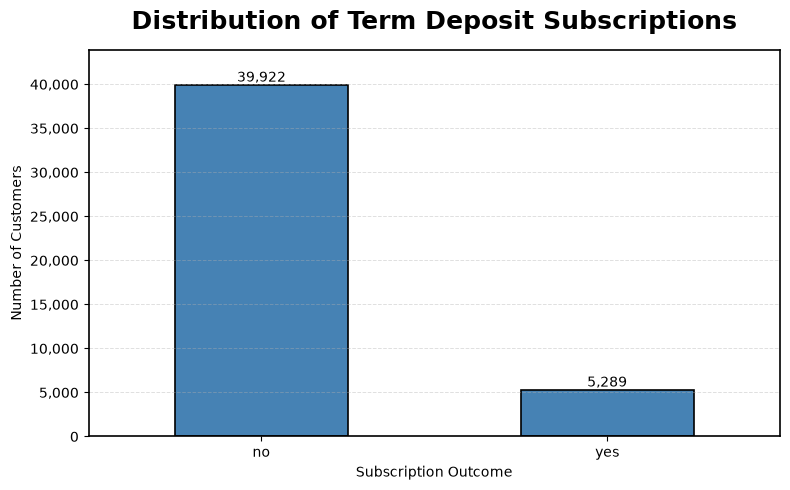

In [58]:
# Create a figure for the subscription distribution chart
plt.figure(figsize = (8,5))
# Create a bar chart to visualize the distribution of term deposit subscriptions
ax = subscription_counts.plot(kind="bar",
                              color = "steelblue",
                              edgecolor = "black",
                              linewidth = 1.2)
# Add a descriptive title
ax.set_title("Distribution of Term Deposit Subscriptions",
             fontsize = 18,
             fontweight = "bold",
             pad = 15
             )
# Display the x-axis labels horizontally
ax.tick_params(axis='x', labelrotation=0)
# Label the axes
ax.set_xlabel("Subscription Outcome",
              fontsize = 10)
ax.set_ylabel("Number of Customers",
              )
# Format the y-axis with comma seperators
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
## Add light horizontal grid lines
ax.grid(
    axis = "y",
    linestyle = "--",
    linewidth = 0.7,
    alpha = 0.4
)
# Strengthen the border around the plotting area
for spine in ax.spines.values():
    spine.set_color("black")
    spine.set_linewidth(1.2)
# Add the count above each bar
ax.bar_label(ax.containers[0], fmt="{:,.0f}")
# Add extra space above the tallest bar
ax.set_ylim(0, subscription_counts.max() * 1.1)
# Adjust spacing so chart elements are not cut off
plt.tight_layout()

## Business Interpretation: Subscription Distribution

### Key Findings

- The dataset is highly imbalanced.
- Approximately 88% of customers did not subscribe to a term deposit.
- Only about 12% of customers accepted the offer.

### Business Interpretation

The bank's direct marketing campaign has a relatively low conversion rate, indicating that most contacted customers do not subscribe to a term deposit. This suggests that contacting every customer is likely inefficient and may result in unnecessary marketing costs.

### Potential Business Impact

A predictive analytics model that identifies customers with a higher likelihood of subscribing could help the bank focus its marketing efforts, reduce unnecessary customer contacts, and improve campaign efficiency.

## Customer Demographics: Age Distribution

### Analysis Question

What does the age distribution of the bank's customers look like, and are there any noticeable patterns that may influence future marketing strategies?

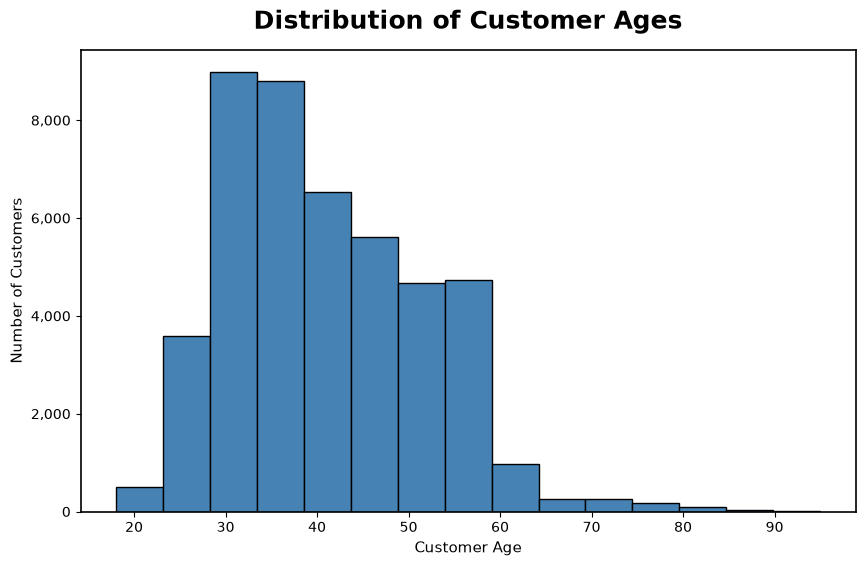

In [59]:
# Create a figure for the age distribution
plt.figure(figsize=(10,6))
#Create a histogram of customer ages
counts, bins, patches = plt.hist(
    df["age"],
    bins = 15,
    edgecolor = "black",
    color = "steelblue"
)
# Add a descriptive title
plt.title(
    "Distribution of Customer Ages",
    fontsize = 18,
    fontweight = "bold",
    pad = 15
)
#Label the x-axis
plt.xlabel(
    "Customer Age",
    fontsize = 11
)
#Label the y-axis
plt.ylabel(
    "Number of Customers",
    fontsize = 11
)

plt.gca().yaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)
# Strengthen the border around the plotting area
ax = plt.gca()

for spine in ax.spines.values():
    spine.set_color("black")
    spine.set_linewidth(1.2)

#Adjust spacing so chart elements are not cut off
plt.tight_layout

#Save the visualization
plt.savefig(
    "../plots/age_distribution.png",
    dpi = 300,
    bbox_inches="tight"
)

## Key Findings

- The customer age distribution is right-skewed, with most customers falling between approximately 30 and 50 years old.
- The largest concentration of customers appears to be in their early- to mid-30s.
- Customer counts gradually decline after age 50, with relatively few customers over the age of 60.
- The dataset includes customers from approximately 18 to over 90 years old, indicating that the bank serves a wide range of age groups.

## Business Interpretation

The bank's customer base is concentrated among working-age adults, particularly customers in their 30s and 40s. While the bank serves customers across a broad range of ages, younger adults and retirees represent a smaller portion of the customer population.

This visualization describes the overall customer base only. Additional analysis is needed to determine whether certain age groups are more likely to subscribe to a term deposit.

## Potential Business Impact

Age is a strong candidate for further analysis because customer financial needs and investment behavior often change throughout different stages of life. Comparing age distributions between subscribers and non-subscribers may reveal whether age is a meaningful predictor of term deposit subscriptions and should be included in the predictive model.

## Customer Demographics: Occupation

### Analysis Question

What occupations make up the bank's customer base, and which occupations are most common?


In [60]:
# Count the number of customers in each occupation
job_counts = df["job"].value_counts()

job_counts

job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64

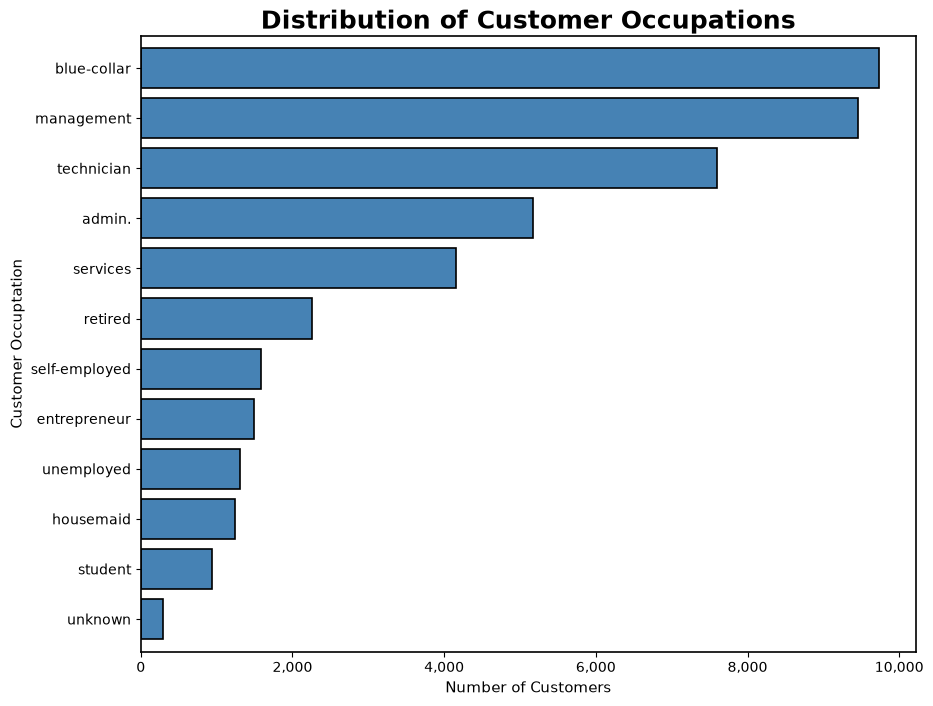

In [61]:
# Create a figure for the occupation distribution
plt.figure(figsize=(10,8))

#Create a horizontal bar chart of customer occupations
ax = job_counts.plot(
    kind = "barh",
    color = "steelblue",
    edgecolor = "black",
    linewidth = 1.2,
    width = 0.8
)

#Display the largest occupation at the top
ax.invert_yaxis()
# Add a descriptive title
ax.set_title("Distribution of Customer Occupations",
             fontsize = 18,
             fontweight = "bold",
             pad = 5
            )
# Labeel the x-axis
ax.set_xlabel(
    "Number of Customers",
    fontsize = 11
)
#label the y-axis
ax.set_ylabel(
        "Customer Occuptation",
        fontsize = 11
    )
# Add commas to number
ax.xaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)
#Strengthen the border around the plotting area
for spine in ax.spines.values():
    spine.set_color("black")
    spine.set_linewidth(1.2)
# Adjust spacing so chart elements are not cut off
ax.figure.tight_layout

#Save the visualization
plt.savefig(
    "../plots/job_distribution.png",
    dpi = 300,
    bbox_inches = "tight"
)

## Key Findings

- Blue-collar workers make up the largest customer segment, followed closely by customers in management roles.
- Technicians and administrative professionals also represent a significant portion of the customer base.
- Students and customers with unknown occupations make up only a small percentage of the dataset.
- The customer base is concentrated in a few major occupation groups rather than being evenly distributed across all occupations.

## Business Interpretation

The bank's customer base is primarily composed of working professionals, particularly blue-collar employees, managers, technicians, and administrative staff. This suggests that future marketing campaigns should focus on the financial needs and communication preferences of these occupations.

At the same time, the relatively small number of students and customers with unknown occupations may indicate opportunities for targeted marketing campaigns designed to expand these underrepresented customer segments.

## Marital Status

### Analysis Question

What is the distribution of customers by marital status?

In [62]:
# Count the number of customers in each marial status category
marital_counts = df["marital"].value_counts()
# Capitalize the marital status labels
marital_counts.index = marital_counts.index.str.title()
marital_counts

marital
Married     27214
Single      12790
Divorced     5207
Name: count, dtype: int64

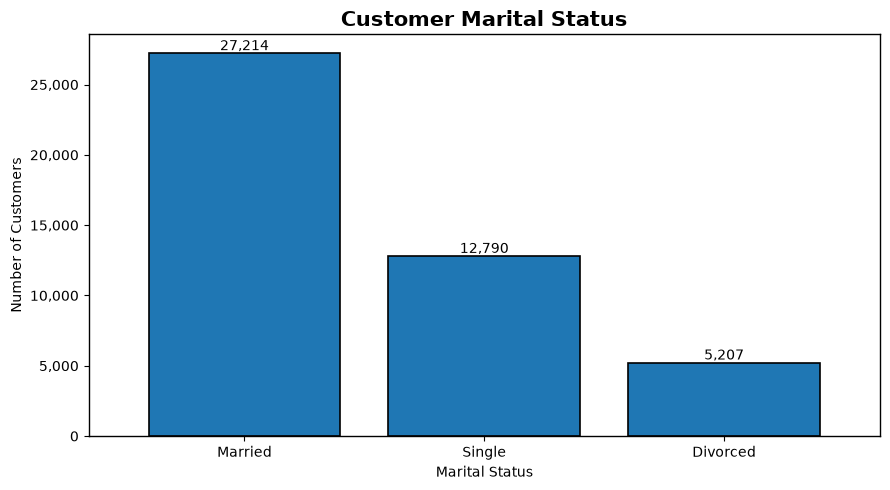

In [63]:
# Create a figure with a professional size
plt.figure(figsize = (9,5))

#Create a horizontal bar chart of marital status counts
ax = marital_counts.plot(
    kind = "bar",
    edgecolor = "black",
    linewidth = 1.2,
    width = 0.8
)

#Add a descriptive title and axis labels
ax.set_title("Customer Marital Status",
             fontsize = 15,
             fontweight = "bold")
ax.set_xlabel("Marital Status")
ax.set_ylabel("Number of Customers")

# Display the x-axis labels horizontally
ax.tick_params(axis = "x", labelrotation =0)
#Format the y-axis to display commas for large numbers
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))



#Add a border around the plot
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1)

#Add the count above each bar
ax.bar_label(ax.containers[0], fmt = "{:,.0f}")

#Add spacing so the labels fit clearly
plt.tight_layout()

#Save the figure for the Github repository
plt.savefig(
    "../plots/marital_distribution.png",
    dpi = 300,
    bbox_inches = "tight"
)

plt.show()


## Key Findings

- Married customers make up the largest customer segment by a substantial margin.
- Single customers represent the second-largest group.
- Divorced customers account for the smallest portion of the customer base.

## Business Interpretation

Most customers in the dataset are married, indicating that the bank's customer base is largely composed of married individuals. Understanding the distribution of marital status provides useful context for future analyses that compare subscription rates across different customer segments.

## Education

### Analysis Question

What is the distribution of customers by education level?

In [64]:
# Count the number of customers in each education category
education_counts = df["education"].value_counts()

#Capitalize the education labels
education_counts.index = education_counts.index.str.title()

education_counts


education
Secondary    23202
Tertiary     13301
Primary       6851
Unknown       1857
Name: count, dtype: int64

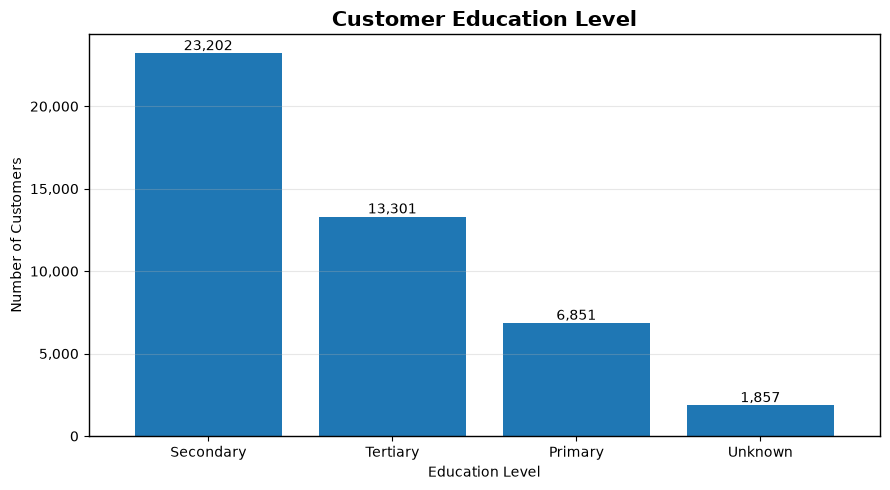

In [65]:
#Create a figure with a professional size
plt.figure(figsize=(9,5))

#Create a vertical bar chart of education counts
ax = education_counts.plot(
    kind = "bar",
    width = 0.8
)

#Add a descriptive title and axis labels
ax.set_title(
    "Customer Education Level",
    fontsize = 15,
    fontweight="bold"
)
ax.set_xlabel("Education Level")
ax.set_ylabel("Number of Customers")

#Format the y-axis to display commas for large numbers
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

#Display x-axis labels horizontally
ax.tick_params(axis = "x", labelrotation = 0)

#Add a border around the plot
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1)

#Add the count above each bar
ax.bar_label(
ax.containers[0],
fmt="{:,.0f}"
)

#Add subtle horizontal gridlines
ax.grid(axis = "y", alpha = 0.3)

#Adjust spacing so labels fit cleanly
plt.tight_layout()

#Save the figure for the github repository
plt.savefig(
    "../plots/education_distribution.png",
    dpi = 300,
    bbox_inches = "tight"
)
#Display the visualization
plt.show()

> **Note:** In this dataset, **Primary** refers to primary school education, **Secondary** refers to high school education, and **Tertiary** refers to college or university education.

## Key Findings

- Customers with secondary education make up the largest customer segment.
- Customers with tertiary education represent the second-largest education group.
- Primary education accounts for a smaller portion of the customer base.
- Only a small percentage of customers have an unknown education level.

## Business Interpretation

The majority of customers have either secondary (high school) or tertiary (college/university) education, while relatively few customers have only primary education or an unknown education level. Understanding the educational composition of the customer base provides valuable context for future analyses that compare subscription rates across education groups.

## Default Status

### Analysis Question

What is the distribution of customers based on whether they have credit in default?


In [66]:
# Count the number of customers in each default status category
default_counts = df["default"].value_counts()

default_counts

default
no     44396
yes      815
Name: count, dtype: int64

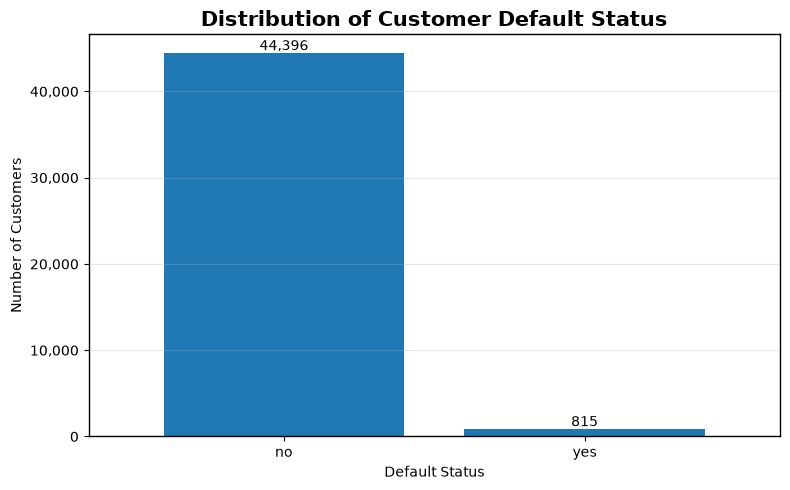

In [67]:
# Create a figure with a professional size
plt.figure(figsize = (8,5))

# Create a vertical bar chart of default status counts
ax = default_counts.plot(
    kind = "bar",
    width = 0.8
)
# Add a descriptive title and axis labels
ax.set_title(
    "Distribution of Customer Default Status",
    fontsize = 15,
    fontweight = "bold"
)
ax.set_xlabel("Default Status")
ax.set_ylabel("Number of Customers")

# #Format the y-axis to display commas for large numbers
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

# Display x-axis labels horizontally
ax.tick_params(axis = "x", labelrotation = 0)

# Add a border around the plot
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1)

# Add a count above each bar
ax.bar_label(
    ax.containers[0],
    fmt = "{:,.0f}"
)

#Add subtle horizontal gridlines
ax.grid(axis = "y", alpha = 0.3)

#Adjust spacing so labels fit cleanly
plt.tight_layout()

#Save the figure for the github repository
plt.savefig(
    "../plots/default_distribution.png",
    dpi = 300,
    bbox_inches = "tight"
)
#Display the visualization
plt.show()

## Key Findings

- Approximately 98% of customers do not have a history of credit default.
- Only 815 customers (about 2%) are classified as being in credit default.
- Customers with credit defaults represent a very small minority of the overall customer base.

## Business Interpretation

The customer base is overwhelmingly composed of individuals without a history of credit default, indicating that the bank primarily serves customers with relatively strong credit profiles. Customers with credit defaults represent only a small portion of the dataset.

Because this variable is highly imbalanced, it may have limited value when considered on its own. However, credit default status may still be an important predictor of term deposit subscriptions when analyzed alongside other customer characteristics in later stages of the project.

# Housing Loan

## About This Variable

The **housing** variable indicates whether a customer currently has a housing loan (mortgage).

Values:
- **Yes** – The customer currently has a housing loan.
- **No** – The customer does not have a housing loan.

### Analysis Question

What is the distribution of customers based on housing loan status?

In [68]:
#Count the number of customers in each housing loan category
housing_counts = df["housing"].value_counts()

housing_counts

housing
yes    25130
no     20081
Name: count, dtype: int64

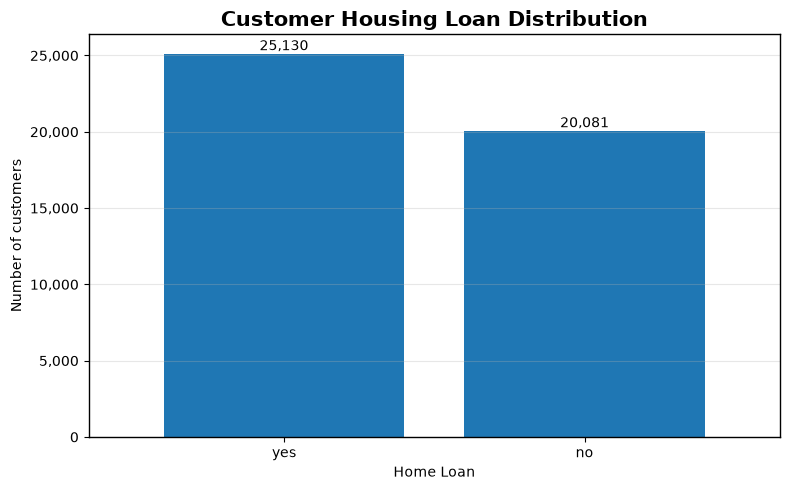

In [69]:
# Create a figure with a professonal size
plt.figure(figsize = (8,5))

#Create a vertical bar chart of housing loan status counts
ax = housing_counts.plot(
    kind = "bar",
    width = 0.8
)
# Add a descriptive title and axis labels
ax.set_title(
    "Customer Housing Loan Distribution",
    fontsize = 15,
    fontweight = "bold"

)
ax.set_xlabel("Home Loan")
ax.set_ylabel("Number of customers")

# # #Format the y-axis to display commas for large numbers
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

# # Display x-axis labels horizontally
ax.tick_params(axis = "x", labelrotation = 0)

# Add a border around the plot
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1)

# Add a count above each bar
ax.bar_label(
    ax.containers[0],
    fmt = "{:,.0f}"
)

# #Add subtle horizontal gridlines
ax.grid(axis = "y", alpha = 0.3)

# #Adjust spacing so labels fit cleanly
plt.tight_layout()

#Save the figure for the github repository
plt.savefig(
    "../plots/housing_distribution.png",
    dpi = 300,
    bbox_inches = "tight"
)
#Display the visualization
plt.show()

## Key Findings

- A slight majority of customers currently have a housing loan.
- Customers with housing loans represent approximately 56% of the dataset.
- Customers without a housing loan account for the remaining 44%, making the distribution relatively balanced.

## Business Interpretation

The customer base is relatively balanced between individuals who currently have a housing loan and those who do not. Unlike credit default status, housing loan ownership is common among customers and may provide useful insight when evaluating marketing performance.

Because both groups are well represented, housing loan status is a strong candidate for future comparative analysis. Later in the project, we will examine whether customers with housing loans are more or less likely to subscribe to a term deposit.

## Personal Loan

### About This Variable

The **loan** variable indicates whether a customer currently has a personal loan.

Values:
- **Yes** – The customer currently has a personal loan.
- **No** – The customer does not have a personal loan.

### Analysis Question

What is the distribution of customers based on personal loan status?

In [70]:
# Count the number of customers in each personal loan category
loan_counts = df["loan"].value_counts()

loan_counts

loan
no     37967
yes     7244
Name: count, dtype: int64

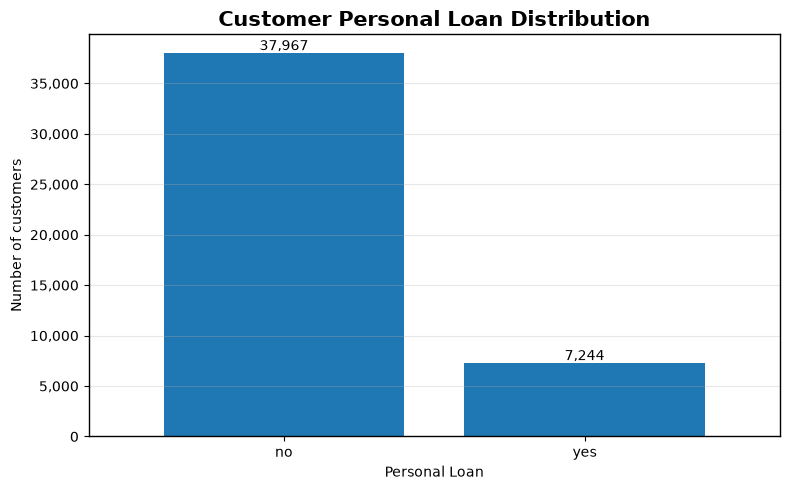

In [71]:
# Create a figure with a professonal size
plt.figure(figsize = (8,5))

#Create a vertical bar chart of housing loan status counts
ax = loan_counts.plot(
    kind = "bar",
    width = 0.8
)
# Add a descriptive title and axis labels
ax.set_title(
    "Customer Personal Loan Distribution",
    fontsize = 15,
    fontweight = "bold"

)
ax.set_xlabel("Personal Loan")
ax.set_ylabel("Number of customers")

# # #Format the y-axis to display commas for large numbers
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

# # Display x-axis labels horizontally
ax.tick_params(axis = "x", labelrotation = 0)

# Add a border around the plot
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1)

# Add a count above each bar
ax.bar_label(
    ax.containers[0],
    fmt = "{:,.0f}"
)

# #Add subtle horizontal gridlines
ax.grid(axis = "y", alpha = 0.3)

# #Adjust spacing so labels fit cleanly
plt.tight_layout()

#Save the figure for the github repository
plt.savefig(
    "../plots/loan_distribution.png",
    dpi = 300,
    bbox_inches = "tight"
)
#Display the visualization
plt.show()

## Key Findings

- The majority of customers do not currently have a personal loan.
- Approximately 38,000 customers have no personal loan, while about 7,200 customers do.
- Customers with a personal loan represent a relatively small portion of the overall customer base.

## Business Interpretation

Most customers in the dataset do not carry a personal loan, indicating that personal loans are not common among the bank's customer base. This imbalance suggests that personal loan holders represent a distinct customer segment rather than the typical customer.

Although customers with personal loans make up a minority of the dataset, this variable may still provide valuable insight into customer behavior. In later analyses, we will examine whether customers with existing personal loans are more or less likely to subscribe to a term deposit and whether personal loan status improves the bank's ability to target future marketing campaigns.

## Contact Method

### About This Variable

The **contact** variable indicates the communication method the bank used to contact a customer during the marketing campaign.

Values:
- **Cellular** – The customer was contacted by mobile phone.
- **Telephone** – The customer was contacted by a landline telephone.
- **Unknown** – The contact method was not recorded.

### Analysis Question

What is the distribution of customers based on contact method?

In [72]:
# Count the number of customers in each contact method category
contact_counts = df["contact"].value_counts()

# Capitalize the contact method labels
contact_counts.index = contact_counts.index.str.title()

contact_counts

contact
Cellular     29285
Unknown      13020
Telephone     2906
Name: count, dtype: int64

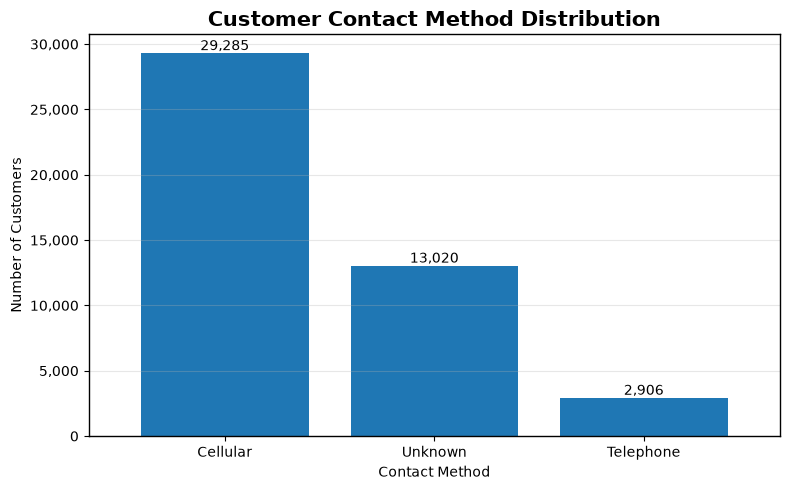

In [73]:
# Create a figure with a professional size
plt.figure(figsize = (8,5))

# Create a vertical bar chart of contact method counts
ax = contact_counts.plot(
    kind = "bar",
    width = 0.8
)

# Add a descriptive title and axis labels
ax.set_title(
    "Customer Contact Method Distribution",
    fontsize = 15,
    fontweight = "bold"
)

ax.set_xlabel("Contact Method")
ax.set_ylabel("Number of Customers")

#Format the y-axis to display commas for large numbers
ax.yaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)
#Display x-axis labels horizontally
ax.tick_params(axis = "x", labelrotation = 0)

# Add a border around the plot
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1)

# Add the count above each bar
ax.bar_label(
    ax.containers[0],
    fmt = "{:,.0f}"
)
# Add subtle horizontal gridlines
ax.grid(axis = "y", alpha = 0.3)

# Add subtle horizontal gridlines
ax.grid(axis = "y", alpha = 0.3)

#Adjust spacing so labels fit cleanly
plt.tight_layout()

# Save the figure for the GitHub repository
plt.savefig(
    "../plots/contact_method_distribution.png",
    dpi = 300,
    bbox_inches = "tight"
)

#Display the visualization
plt.show()

## Key Findings

- Cellular is the most common contact method, accounting for the majority of customer records.
- A substantial number of customer records have an unknown contact method.
- Telephone is the least common contact method, representing only a small portion of the dataset.

## Business Interpretation

The bank primarily relied on cellular phones to contact customers during the marketing campaign, indicating that mobile communication was the preferred outreach method. In contrast, telephone contacts represent only a small fraction of the customer base.

A notable portion of customer records contain an unknown contact method. This may reflect missing or incomplete data and could affect analyses involving communication channels.

These results describe how customers were contacted rather than how effective each method was. In the comparative analysis section, we will examine whether the method of contact influences a customer's likelihood of subscribing to a term deposit.

## About This Variable

The **month** variable indicates the month in which the customer was last contacted during the bank's marketing campaign.

Values:

- Jan – January
- Feb – February
- Mar – March
- Apr – April
- May – May
- Jun – June
- Jul – July
- Aug – August
- Sep – September
- Oct – October
- Nov – November
- Dec – December

This variable represents **when** the customer was contacted, not when they opened an account or subscribed to a term deposit.

## Analysis Question

What is the distribution of customers contacted across each month?

In [74]:
# Count the number of customers contacted in each month
month_counts = df["month"].value_counts()

# Arrange the months in chronological order
month_order = [
    "jan", "feb", "mar", "apr",
    "may", "jun", "jul", "aug",
    "sep", "oct", "nov", "dec"
]

month_counts = month_counts.reindex(month_order)

#Capitilize the month labels
month_counts.index = month_counts.index.str.title()

month_counts

month
Jan     1403
Feb     2649
Mar      477
Apr     2932
May    13766
Jun     5341
Jul     6895
Aug     6247
Sep      579
Oct      738
Nov     3970
Dec      214
Name: count, dtype: int64

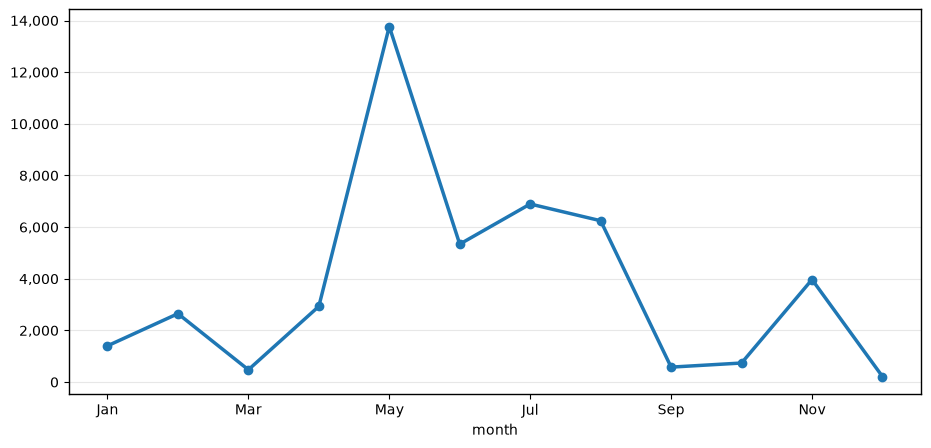

In [75]:
# Create a figure with a professional size
plt.figure(figsize = (11,5))

# Create a line chart showing customer contacts by month
ax = month_counts.plot(
    kind = "line",
    marker = "o",
    linewidth = 2.5
)

# Format the y-axis to display commas for large numbers
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

# Add subtle horizontal gridlines
ax.grid(
    axis = "y",
    alpha = 0.3
)

# Add a border around the plot
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1)

# Save the figure 
plt.savefig(
    "../plots/month_distribution.png",
    dpi = 300,
    bbox_inches = "tight"
)

# Display the visualization
plt.show()

 ## Key Findings

- Customer contact activity was concentrated within a few months rather than being evenly distributed throughout the year.
- May recorded the highest number of customer contacts by a substantial margin, making it the busiest month of the campaign.
- Contact activity remained relatively high during June, July, and August before declining sharply in September.
- Very little customer outreach occurred during the final months of the year, particularly in December.

## Business Interpretation

The distribution of customer contacts suggests the bank followed a seasonal marketing strategy instead of conducting outreach consistently throughout the year. The sharp increase in contacts during May, followed by sustained activity through the summer months, indicates that marketing resources were concentrated during a specific campaign period.

While this visualization shows when customers were contacted, it does not indicate whether those contacts resulted in successful term deposit subscriptions. A later comparative analysis will examine whether certain months achieved higher subscription rates and whether increased marketing activity translated into improved campaign performance.